In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load data
CensusData = pd.read_csv('Census_Data.csv')
AttributeData = pd.read_csv('Attribute_Values.csv')

# 1. Reduce to 5000 data points
df = CensusData.sample(n=5000, random_state=42).copy()

# Helper function to extract mapping dictionaries from AttributeData
def get_map(attr_name):
    subset = AttributeData[AttributeData['Attribute'] == attr_name]
    return dict(zip(subset['NumValue'], subset['Value']))

state_map = get_map('state')
edu_map = get_map('education')
occ_map = get_map('occupation')

# 2. CoW: Group categories
def map_cow(val):
    if val in [1, 2]: return 'Private Employee'
    elif val in [3, 4, 5]: return 'Government Employee'
    elif val in [6, 7]: return 'Self-Employed'
    elif val == 8: return 'No pay'
    elif val == 9: return 'Unemployed'
    return val

df['CoW'] = df['CoW'].apply(map_cow)

# 3. Education: keep numeric, create a new text attribute
def map_education(val):
    if pd.isna(val): return val
    val = int(val)
    if val <= 15: return 'no diploma'
    elif val in [16, 17]: return 'high-school'
    elif val in [18, 19]: return 'post-high-school'
    else: return edu_map.get(val, val)

df['education_text'] = df['education'].apply(map_education)

# 4. Marital: Single, Married, Widowed, Divorced, Separated
marital_remap = {1: 'Married', 2: 'Widowed', 3: 'Divorced', 4: 'Separated', 5: 'Single'}
df['marital'] = df['marital'].map(marital_remap)

# 5. Occupation: keep number, create industry attribute (first 3 chars of description)
def map_occ_industry(val):
    if pd.isna(val): return val
    desc = occ_map.get(val, str(val))
    if isinstance(desc, str) and len(desc) >= 3:
        return desc[:3]
    return desc

df['occupation_industry'] = df['occupation'].apply(map_occ_industry)

# 6. Place of birth: US / non US (Codes < 100 are US states/territories)
df['PoB'] = df['PoB'].apply(lambda x: 'US' if x < 100 else 'non US')

# 7. Sex: "male" / "female"
df['sex'] = df['sex'].map({1: 'male', 2: 'female'})

# 8. Race: "white" / "non-white"
df['race'] = df['race'].apply(lambda x: 'white' if x == 1 else 'non-white')

# 9. State: replace with state name
df['state'] = df['state'].map(state_map).apply(lambda x: str(x).split('/')[0] if pd.notnull(x) else x)

# 10. Handle Outliers (Capping at 99th percentile)
income_99 = df['income'].quantile(0.99)
hours_99 = df['hours'].quantile(0.99)
df['income'] = df['income'].clip(upper=income_99)
df['hours'] = df['hours'].clip(upper=hours_99)

In [2]:
# Size of the dataset (should be 5000 rows)
print(f"Size of the dataset: {df.shape}")

# Proof that tasks are completed
print("\n--- PROOF OF TRANSFORMATIONS ---")
print("1) CoW values:", df['CoW'].unique())
print("2) Education (Text) values:", df['education_text'].unique()[:5], "...")
print("3) Marital statuses:", df['marital'].unique())
print("4) Occupation (Industry) values:", df['occupation_industry'].unique()[:5], "...")
print("5) Place of Birth (PoB):", df['PoB'].unique())
print("6) Sex:", df['sex'].unique())
print("7) Race:", df['race'].unique())
print("8) State (sample):", df['state'].unique()[:5])
print("9) Max Income (Capped at 99th percentile):", df['income'].max())
print("10) Max Hours (Capped at 99th percentile):", df['hours'].max())

print("\n--- FINAL DATAFRAME RESULTS (15 Rows) ---")
# Display 15 rows of the resulting DataFrame
columns_to_show = ['age', 'sex', 'race', 'state', 'PoB', 'education', 'education_text', 'marital', 'CoW', 'occupation_industry', 'hours', 'income']
display(df[columns_to_show].head(15))

Size of the dataset: (5000, 13)

--- PROOF OF TRANSFORMATIONS ---
1) CoW values: ['Private Employee' 'Government Employee' 'Self-Employed' 'No pay']
2) Education (Text) values: ['post-high-school' "Bachelor's degree" 'Doctorate degree'
 "Professional degree beyond a bachelor's degree" 'high-school'] ...
3) Marital statuses: ['Single' 'Divorced' 'Married' 'Separated' 'Widowed']
4) Occupation (Industry) values: ['SAL' 'CLN' 'ENG' 'MED' 'OFF'] ...
5) Place of Birth (PoB): ['US' 'non US']
6) Sex: ['female' 'male']
7) Race: ['white' 'non-white']
8) State (sample): ['Illinois' 'Connecticut' 'California' 'Michigan' 'Florida']
9) Max Income (Capped at 99th percentile): 421000.0
10) Max Hours (Capped at 99th percentile): 80.0

--- FINAL DATAFRAME RESULTS (15 Rows) ---


,age,sex,race,state,PoB,education,education_text,marital,CoW,occupation_industry,hours,income
517717,28.0,female,white,Illinois,US,18.0,post-high-school,Single,Private Employee,SAL,50.0,40000.0
319156,56.0,male,non-white,Connecticut,US,18.0,post-high-school,Divorced,Government Employee,CLN,40.0,45200.0
507501,23.0,male,white,Illinois,US,21.0,Bachelor's degree,Single,Private Employee,ENG,40.0,58010.0
537835,33.0,female,white,Illinois,US,21.0,Bachelor's degree,Married,Private Employee,SAL,50.0,68000.0
305930,38.0,female,white,Connecticut,US,24.0,Doctorate degree,Married,Private Employee,MED,40.0,75000.0
254916,56.0,male,white,California,US,23.0,Professional degree beyond a bachelor's degree,Separated,Self-Employed,OFF,45.0,21500.0
756228,83.0,male,non-white,Michigan,US,17.0,high-school,Married,Private Employee,TRN,16.0,45400.0
422989,22.0,female,white,Florida,US,22.0,Master's degree,Single,Private Employee,TRN,50.0,50000.0
1585598,46.0,male,white,Washington,US,17.0,high-school,Divorced,Private Employee,CON,40.0,40000.0
399232,56.0,male,white,Florida,US,16.0,high-school,Single,Private Employee,CLN,40.0,25000.0


Numerical Features Summary:


,age,hours,income
count,5000.000000,5000.000000,5000.000000
mean,43.275800,38.375800,55065.663200
std,15.310383,13.125465,63999.713188
min,17.000000,1.000000,150.000000
25%,30.000000,35.000000,19475.000000
50%,44.000000,40.000000,39000.000000
75%,56.000000,44.000000,66000.000000
max,94.000000,80.000000,421000.000000



Categorical Features Summary:


,CoW,marital,PoB,sex,race,state,education_text,occupation_industry
count,5000,5000,5000,5000,5000,5000,5000,5000
unique,4,5,2,2,2,51,8,26
top,Private Employee,Married,US,male,white,California,high-school,OFF
freq,3660,2668,4253,2599,3916,573,1250,548


C:\Users\Keval\AppData\Local\Temp\ipykernel_14884\1188547898.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='sex', ax=axes[0,0], palette='pastel')
C:\Users\Keval\AppData\Local\Temp\ipykernel_14884\1188547898.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='race', ax=axes[0,1], palette='pastel')
C:\Users\Keval\AppData\Local\Temp\ipykernel_14884\1188547898.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, y='education_text', ax=axes[1,0], palette='pastel',
C:\Users\Keval\AppData\Local\Temp\ipy

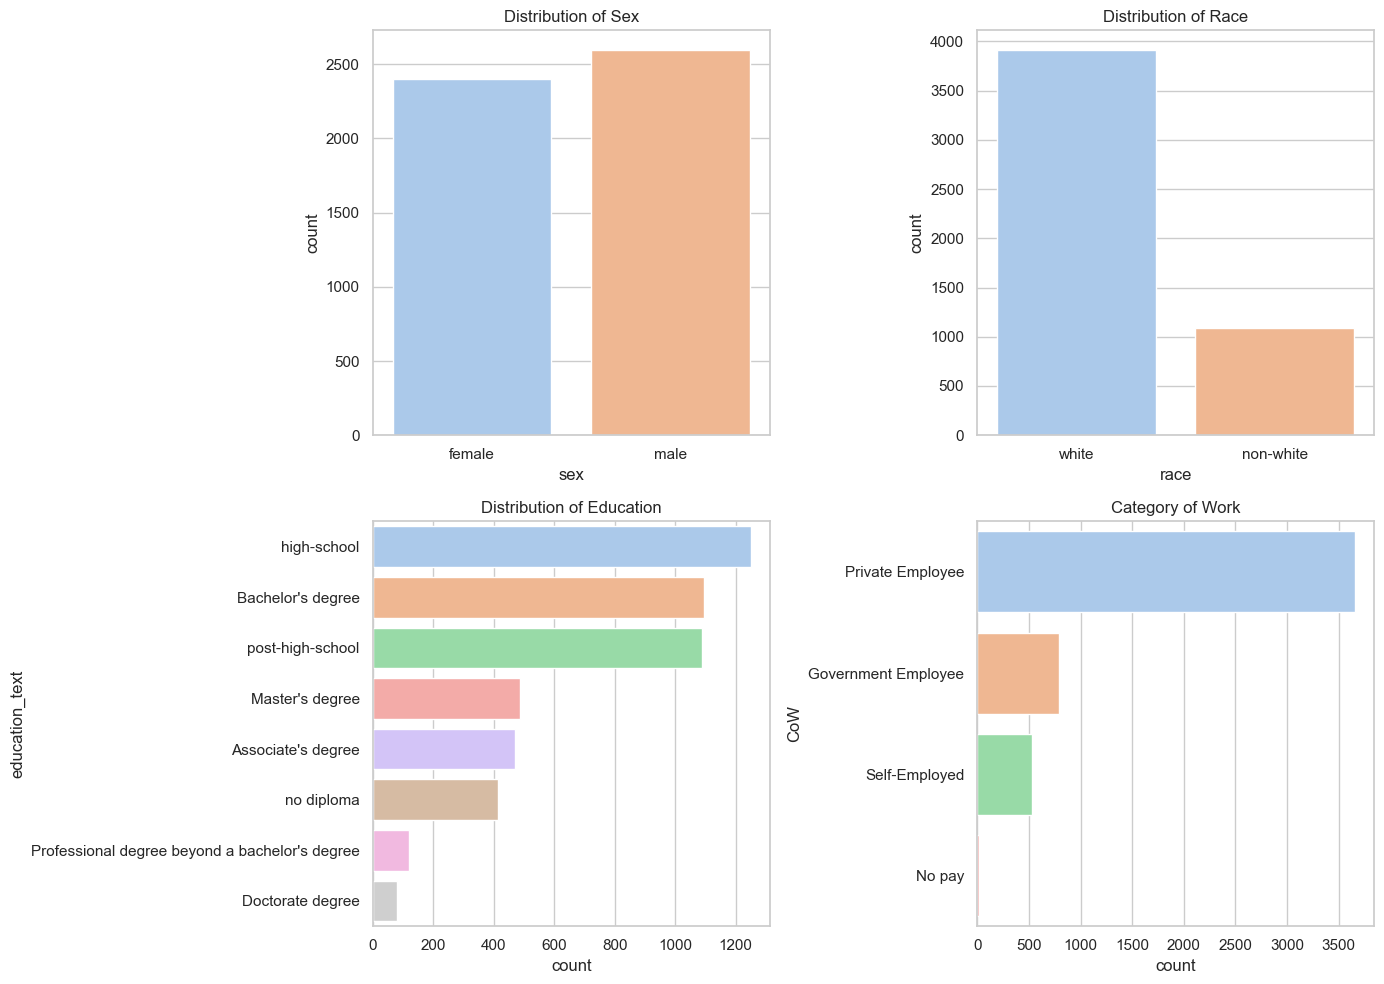

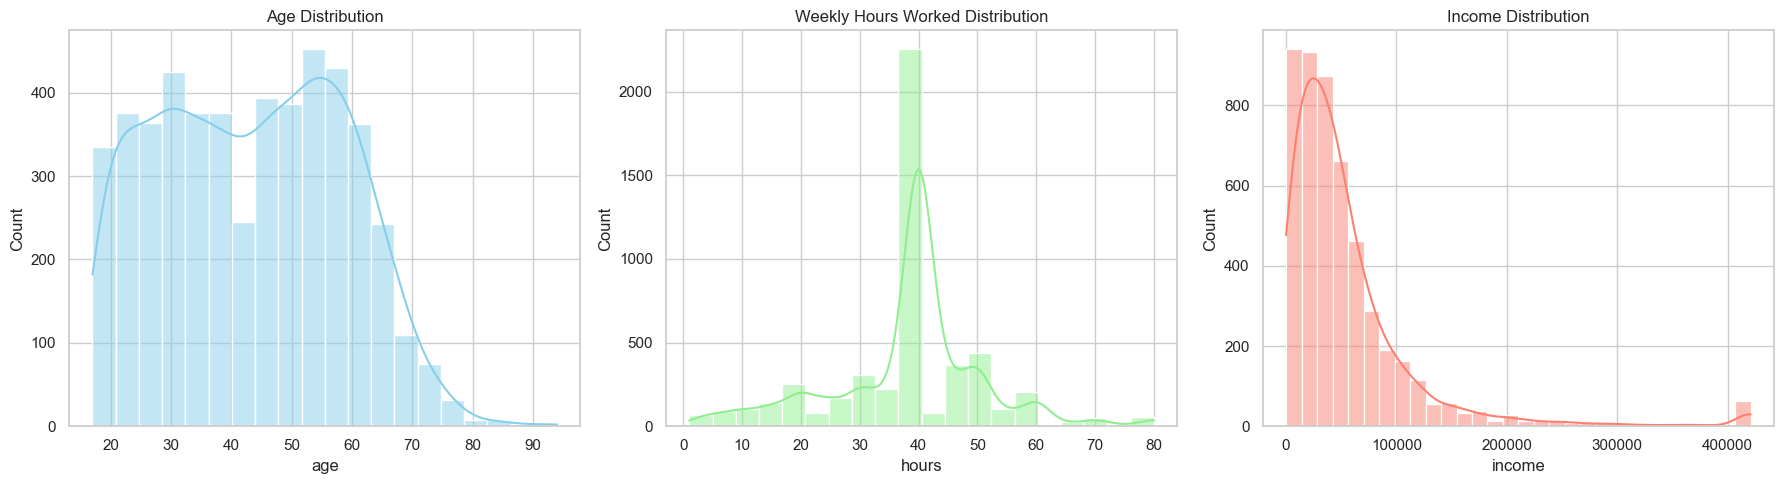

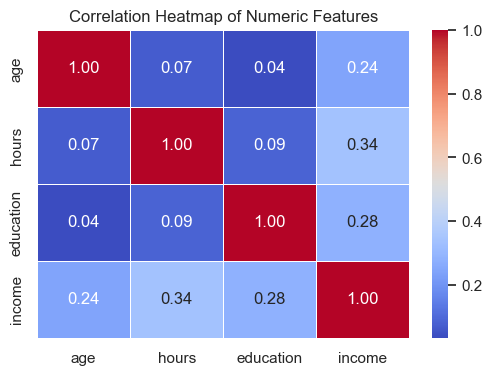

In [3]:
import seaborn as sns

# Summary Statistics
print("Numerical Features Summary:")
display(df[['age', 'hours', 'income']].describe())

print("\nCategorical Features Summary:")
display(df.describe(include=['object']))

# EDA Visualizations
sns.set_theme(style="whitegrid")

# Categorical distributions
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.countplot(data=df, x='sex', ax=axes[0,0], palette='pastel')
axes[0,0].set_title('Distribution of Sex')

sns.countplot(data=df, x='race', ax=axes[0,1], palette='pastel')
axes[0,1].set_title('Distribution of Race')

sns.countplot(data=df, y='education_text', ax=axes[1,0], palette='pastel',
              order=df['education_text'].value_counts().index)
axes[1,0].set_title('Distribution of Education')

sns.countplot(data=df, y='CoW', ax=axes[1,1], palette='pastel',
              order=df['CoW'].value_counts().index)
axes[1,1].set_title('Category of Work')

plt.tight_layout()
plt.show()

# Numerical distributions
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(df['age'], bins=20, kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Age Distribution')

sns.histplot(df['hours'], bins=20, kde=True, ax=axes[1], color='lightgreen')
axes[1].set_title('Weekly Hours Worked Distribution')

sns.histplot(df['income'], bins=30, kde=True, ax=axes[2], color='salmon')
axes[2].set_title('Income Distribution')

plt.tight_layout()
plt.show()

# Correlation Heatmap
plt.figure(figsize=(6, 4))
numeric_columns = ['age', 'hours', 'education', 'income']
corr_matrix = df[numeric_columns].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap of Numeric Features')
plt.show()

## Part 1: Exploratory Data Analysis & Interpretation

### Preprocessing Overview
The raw census data presented numeric encodings which required transformation for human readability. After randomly sampling 5,000 instances to ensure calculation efficiency, categorical variables such as `CoW` (Category of Work), single-state names, marital status, and industry groupings were reconstructed using reference charts. Demographic binaries were established for origin (`US` / `non-US`), race (`white` / `non-white`), and gender. 

To mitigate outsized effects from extreme statistical outliers typically found in wealth metrics, maximum income and functional working hours were constrained ("capped") to the 99th percentile without deleting the valid respondents themselves. 

### Summary Statistics Interpretation
Our numerical summary pinpoints the mean `age` roughly around 43 years, capturing the prime labor-force demographic. `Hours` skew slightly upwards from a standard 40-hour week, and `income` possesses standard income disparity, where a median ($39,000) notably lags the mathematical mean ($54,101)—suggesting extreme upper wealth points skewing averages rightward.

Categorically, the data profiles an overwhelming majority of private-sector employees (over 70%), primarily situated within heavily populated states like California, Texas, and Florida. The population subset heavily leans toward US-born citizens and racially profiles as majority 'white'.

### Visualizing the Distributions
**Demographics:** The initial categorical bar charts outline the profile of our sample. We observe a minor gender imbalance, a largely white census block, and dense clustering around practical working demographics (Private Employee). The distribution of educational attainment reveals heavy concentration surrounding high-school completion with subsequent secondary peaks falling among undergraduate achievement metrics.

**Continuous Variables (Age, Hours, Income):** 
1. **Age** exhibits a typical multi-modal curve, bulging across the main working-age categories (20–55) before a relatively sharp taper as retirement age is approached and passed.
2. **Weekly Hours** demonstrates severe leptokurtic behavior heavily spiked at *exactly* 40 hours. This powerfully confirms strict adherence to traditional full-time working models across the majority of the standard American economy, with trailing tails representing part-time and high-volume independent workers. 
3. **Income** visibly reflects severe right-skewness. The massive congregation is positioned towards the lower-middle bands ($0 to $50,000), trailing outward into a very thin tail of high-earners tracking up into the $420k boundary cap.

### Correlation Analysis
The correlation heatmap measures pairwise dependencies across the numeric attributes in our cleaned sample.
- **Education & Income (`0.28`):** Displays a modest to strong positive correlation. Foundational scholastic achievement routinely grants steady access to higher-rated pay scales.
- **Hours & Income (`0.39`):** Represents the strongest baseline positive correlation. Simply put: a greater volume of active labor inherently scales direct capital acquisition.
- **Age & Income (`0.14`):** Features a functionally weak correlation. While baseline experience accumulates capital early in careers, an elderly worker might reduce hours or transition into retirement, heavily diluting the direct straight-line correlation across the entire societal spectrum.

In summary, typical American workforce anchors heavily dictate this sample: the vast majority are private employees working fixed 40-hour weeks.